In [1]:
import geopandas as gpd
import pandas as pd
import pyogrio
import matplotlib.pyplot as plt
import re
import unicodedata
import numpy as np

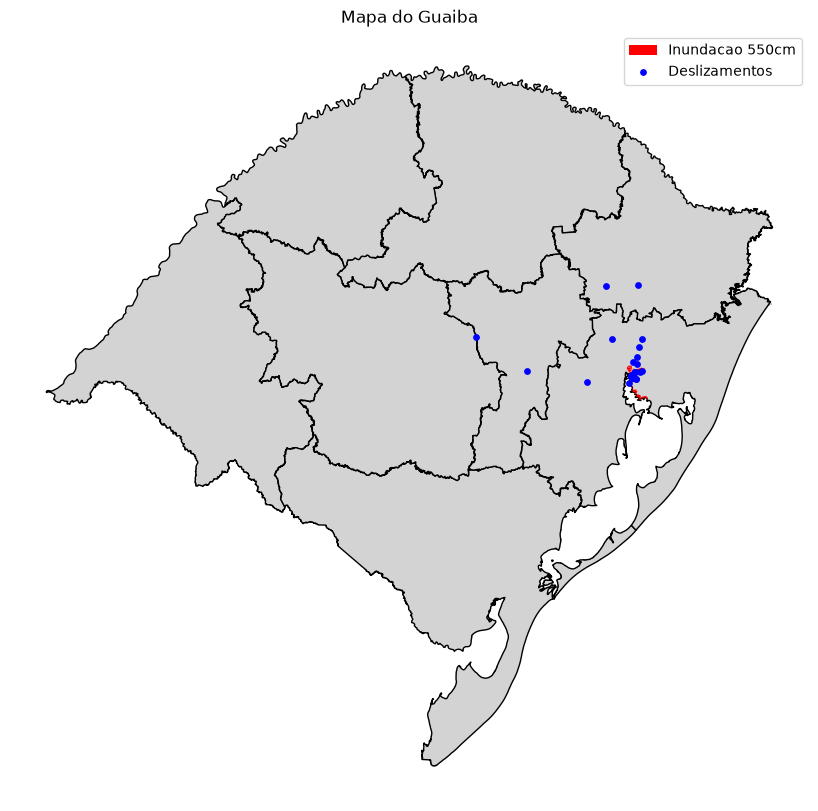

In [19]:
arquivo = "../dados/cheias_rhguaiba_2024_db_v14.gpkg"
arquivo2 = "../dados/mapa_RS_intermediaria/RS_RG_Intermediarias_2025.shp"

mapa = gpd.read_file(arquivo2)

pontos = gpd.read_file(
    arquivo,
    layer="poa_inundacao_simulada_550cm"
)

pontos2 = gpd.read_file(
    arquivo,
    layer="rs_crise_patrimonio_cultural"
)

pontos = pontos.to_crs(mapa.crs)
pontos2 = pontos2.to_crs(mapa.crs)

fig, ax = plt.subplots(figsize=(12, 10))

mapa.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black"
)

pontos.plot(
    ax=ax,
    color="red",
    markersize=15,
    marker="o",
    label="Inundacao 550cm"
)

pontos2.plot(
    ax=ax,
    color="blue",
    markersize=15,
    marker="o",
    label="Deslizamentos"
)


ax.legend()
ax.set_title("Mapa do Guaiba")
ax.set_axis_off()

plt.show()

In [20]:
gdf = gpd.read_file("../dados/cheias_rhguaiba_2024_db_v14.gpkg")

print(gdf.head())

         nmbop  cdbop               nmrop cdrop  \
0    AGRONOMIA  BOP71   LOMBA DO PINHEIRO  OP04   
1     ANCHIETA  BOP19  HUMAITA-NAVEGANTES  OP01   
2  ARQUIPELAGO  BOP36               ILHAS  OP17   
3  AUXILIADORA  BOP01              CENTRO  OP16   
4       AZENHA  BOP02              CENTRO  OP16   

                                      nmrp  cdrp   cota_mean  \
0             LOMBA DO PINHEIRO - PARTENON  RP07  125.157306   
1  HUMAITA - NAVEGANTES - ILHAS E NOROESTE  RP02    1.954820   
2  HUMAITA - NAVEGANTES - ILHAS E NOROESTE  RP02    1.162602   
3                                   CENTRO  RP01   28.703022   
4                                   CENTRO  RP01   12.897710   

                                            geometry  
0  MULTIPOLYGON Z (((489305.255 6676873.088 0, 48...  
1  MULTIPOLYGON Z (((484961.018 6685092.233 0, 48...  
2  MULTIPOLYGON Z (((471983.597 6674237.441 0, 47...  
3  MULTIPOLYGON Z (((482207 6678761.422 0, 482243...  
4  MULTIPOLYGON Z (((479842.718 6

c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\pyogrio\geopandas.py:382: UserWarning: More than one layer found in 'cheias_rhguaiba_2024_db_v14.gpkg': 'poa_admin_bairros' (default), 'poa_inundacao_1941_475cm', 'poa_inundacao_1967_313cm', 'poa_inundacao_2015_294cm', 'poa_inundacao_2023_nov_346cm', 'poa_inundacao_2023_set_318cm', 'poa_inundacao_2024_530cm', 'poa_inundacao_simulada_500cm', 'poa_inundacao_simulada_550cm', 'poa_inundacao_simulada_600cm', 'poa_inundacao_simulada_650cm', 'poa_inundacao_simulada_700cm', 'poa_sb_agua_fontes_publicas', 'poa_sb_agua_saa', 'rhguaiba_bacia', 'rhguaiba_sentinel2_agua_obs_20240506', 'rhguaiba_hecras_inundacao_simulada_550cm', 'rs_crise_abrigos_08052024_12h', 'rmpa_sb_agua_fontes_publicas', 'rs_crise_abrigos_09052024_20h', 'rhguaiba_sentinel2_agua_obs_06052024_validada', 'rs_crise_abrigos_10052024_13h', 'rs_crise_abrigos_10052024_20h', 'rs_crise_abrigos_11052024_13h', 'rs_crise_abrigos_11052024_18h', 'rhguaiba_hecras_severida

In [21]:
camadas = pyogrio.list_layers("../dados/cheias_rhguaiba_2024_db_v14.gpkg")
print(camadas)

[['poa_admin_bairros' 'MultiPolygon Z']
 ['poa_inundacao_1941_475cm' 'MultiPolygon']
 ['poa_inundacao_1967_313cm' 'MultiPolygon']
 ['poa_inundacao_2015_294cm' 'MultiPolygon']
 ['poa_inundacao_2023_nov_346cm' 'Polygon']
 ['poa_inundacao_2023_set_318cm' 'MultiPolygon']
 ['poa_inundacao_2024_530cm' 'MultiPolygon']
 ['poa_inundacao_simulada_500cm' 'MultiPolygon']
 ['poa_inundacao_simulada_550cm' 'MultiPolygon']
 ['poa_inundacao_simulada_600cm' 'Polygon']
 ['poa_inundacao_simulada_650cm' 'Polygon']
 ['poa_inundacao_simulada_700cm' 'Polygon']
 ['poa_sb_agua_fontes_publicas' 'Point Z']
 ['poa_sb_agua_saa' 'MultiPolygon']
 ['rhguaiba_bacia' 'MultiPolygon Z']
 ['rhguaiba_sentinel2_agua_obs_20240506' 'Polygon']
 ['rhguaiba_hecras_inundacao_simulada_550cm' 'Polygon Z']
 ['rs_crise_abrigos_08052024_12h' 'Point']
 ['rmpa_sb_agua_fontes_publicas' 'Point Z']
 ['rs_crise_abrigos_09052024_20h' 'Point']
 ['rhguaiba_sentinel2_agua_obs_06052024_validada' 'Polygon']
 ['rs_crise_abrigos_10052024_13h' 'Point

---
# rmpa_crise_sb_ebaps_{data}

Quantidade de instancias = 1 <br>

Problemas:
- Muitos dos valores de situacao sao "APURAR"
- Coluna "Endereco" nao eh usado ("None")

In [22]:
gdf = gpd.read_file(
    "../dados/cheias_rhguaiba_2024_db_v14.gpkg",
    layer="rmpa_crise_sb_ebaps_20240524"
)

print(gdf.to_string())

    Id                        Nome Completo         NM_MUN SG_MUN  Nome_1                 Nome_2 Endereco   Latitude  Longitude Situ_2024_05_01 Situ_2024_05_02 Situ_2024_05_03 Situ_2024_05_04 Situ_2024_05_05 Situ_2024_05_06 Situ_2024_05_07 Situ_2024_05_08 Situ_2024_05_09 Situ_2024_05_10 Situ_2024_05_11 Situ_2024_05_12 Situ_2024_05_13 Situ_2024_05_14 Situ_2024_05_15 Situ_2024_05_16 Situ_2024_05_17 Situ_2024_05_18 Situ_2024_05_19 Situ_2024_05_20 Situ_2024_05_21 Situ_2024_05_22 Situ_2024_05_23 Situ_2024_05_24 Situ_2024_05_25 Situ_2024_05_26                     geometry
0    1                   EBAP_SL_CB_Ginasio   São Leopoldo     SL      CB                Ginasio     None -29.758328 -51.143852          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          APURAR          AP

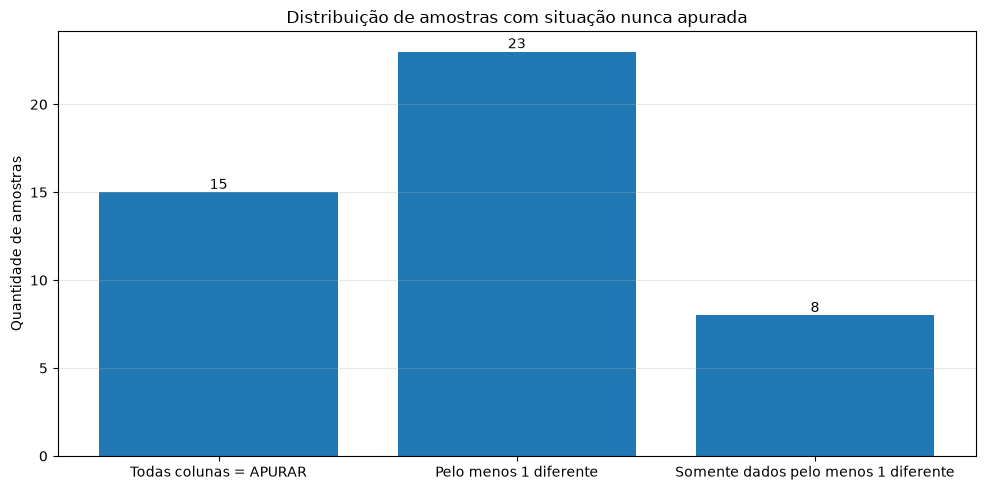

In [ ]:
colunas = [
    'Situ_2024_05_01',
    'Situ_2024_05_02',
    'Situ_2024_05_03',
    'Situ_2024_05_04',
    'Situ_2024_05_05',
    'Situ_2024_05_06',
    'Situ_2024_05_07',
    'Situ_2024_05_08',
    'Situ_2024_05_09',
    'Situ_2024_05_10',
    'Situ_2024_05_11',
    'Situ_2024_05_12',
    'Situ_2024_05_13',
    'Situ_2024_05_14',
    'Situ_2024_05_15',
    'Situ_2024_05_16',
    'Situ_2024_05_17',
    'Situ_2024_05_18',
    'Situ_2024_05_19',
    'Situ_2024_05_20',
    'Situ_2024_05_21',
    'Situ_2024_05_22',
    'Situ_2024_05_23',
    'Situ_2024_05_24',
    'Situ_2024_05_25',
    'Situ_2024_05_26'
]

# Todas as colunas sao APURAR
mascara_todos_apurar = gdf[colunas].eq('APURAR').all(axis=1)

# Pelo menos uma coluna eh diferente de APURAR
mascara_algum_diferente = ~mascara_todos_apurar

# Contagem
quantidade_todos_apurar = mascara_todos_apurar.sum()
quantidade_algum_diferente = mascara_algum_diferente.sum()
diferenca = abs(quantidade_todos_apurar - quantidade_algum_diferente)

categorias = [
    'Todas colunas = APURAR',
    'Pelo menos 1 diferente',
    'Somente dados pelo menos 1 diferente'
]

quantidades = [
    quantidade_todos_apurar,
    quantidade_algum_diferente,
    diferenca
]

plt.figure(figsize=(10, 5))

barras = plt.bar(categorias, quantidades)

plt.title('Distribuição de amostras com situação nunca apurada')
plt.ylabel('Quantidade de amostras')

plt.bar_label(barras, fmt='%d')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
gdf = gpd.read_file(
    "../dados/cheias_rhguaiba_2024_db_v14.gpkg",
    layer="rmpa_crise_sb_ebaps_20240524"
)

#todas as colunas de dias
cols_situ = [c for c in gdf.columns if c.startswith("Situ_")]

cols_sem_dado =[
    c for c in cols_situ
    if gdf[c].fillna("APURAR").eq("APURAR").all()
]

#tirar colunas desnecessarias
cols_drop = ["Id", "Endereco", "Latitude", "Longitude", "Nome_1", "SG_MUN", "NM_MUN"] + cols_sem_dado
gdf = gdf.drop(columns=cols_drop, errors="ignore")

#recalcular as colunas dps q foram retiradas algumas
cols_situ = [c for c in gdf.columns if c.startswith("Situ_")]

def sem_informacao(linha):
    valores = linha.fillna("APURAR")
    return (valores=="APURAR").all()

mask_nunca_muda = gdf[cols_situ].apply(sem_informacao, axis=1)
print(f"Estações removidas: {mask_nunca_muda.sum()} de {len(gdf)}")

gdf_limpo = gdf.loc[~mask_nunca_muda].reset_index(drop=True)

print(gdf_limpo.shape)
print(gdf_limpo.to_string())
gdf_limpo.to_file("rmpa_crise_sb_ebaps_limpo.gpkg", layer="gdf_limpo", driver="GPKG")

Estações removidas: 15 de 38
(23, 23)
                          Nome Completo                 Nome_2 Situ_2024_05_03 Situ_2024_05_04 Situ_2024_05_06 Situ_2024_05_08 Situ_2024_05_09 Situ_2024_05_10 Situ_2024_05_11 Situ_2024_05_12 Situ_2024_05_13 Situ_2024_05_14 Situ_2024_05_15 Situ_2024_05_16 Situ_2024_05_17 Situ_2024_05_18 Situ_2024_05_19 Situ_2024_05_20 Situ_2024_05_21 Situ_2024_05_22 Situ_2024_05_23 Situ_2024_05_24                     geometry
0              EBAP_PA_CB 01_Rodoviaria             Rodoviaria      Inoperante          APURAR        Operante        Operante        Operante        Operante      Inoperante      Inoperante      Inoperante      Inoperante      Inoperante      Inoperante      Inoperante      Inoperante      Inoperante      Inoperante      Inoperante      Inoperante      Inoperante      Inoperante  POINT (-51.21601 -30.01929)
1                EBAP_PA_CB 02_Sao Joao               Sao Joao      Inoperante          APURAR        Operante      Inoperante      Inoper

---
# rs_crise_abrigos_{data}_{hora}
Quantidade de instancias = 14 <br>

Problemas:
- Conj. de dados muito grande
- Cada dataset tem um padrao diferente (ate relatorios de mesmo dia mas horas diferentes)
- Vai precisar usar menos da metade disponivel para conseguir usar

In [25]:
gdf = gpd.read_file(
    "../dados/cheias_rhguaiba_2024_db_v14.gpkg",
    layer="rs_crise_abrigos_24052024_20h"
)
#rs_crise_abrigos_08052024_12h
#rs_crise_abrigos_09052024_20h
#rs_crise_abrigos_10052024_13h
#rs_crise_abrigos_10052024_20h
#rs_crise_abrigos_11052024_13h
#rs_crise_abrigos_11052024_18h
#rs_crise_abrigos_13052024_09h
#rs_crise_abrigos_14052024_22h
#rs_crise_abrigos_15052024_22h
#rs_crise_abrigos_17052024_21h
#rs_crise_abrigos_21052024_21h
#rs_crise_abrigos_22052024_21h
#rs_crise_abrigos_23052024_21h
#rs_crise_abrigos_24052024_20h

print(gdf.to_string())

                                                                                              NAME               TIPO DE LOCAL (VALIDADO UFRGS)                            TIPO DE LOCAL (NÃO VALIDADO)                                                                                                ENDEREÇO                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                O QUE ESTÁ FALTANDO                                                      

In [26]:
# ========= CONFIGURAÇÕES =========
GPKG = "../dados/cheias_rhguaiba_2024_db_v14.gpkg"
PREFIXO = "rs_crise_abrigos_"

# variacoes dos nomes das colunas
COLUNAS_NOME = ["nome", "name"]
COLUNAS_TIPO = ["tipo_de_local", "tipo_local", "tipo_do_local", "tipo_de_abrigo", "tipo", "Tipo", "TIPO DE LOCAL", "TIPO DE LOCAL (VALIDADO UFRGS)", "TIPO DE LOCAL (classificação UFRGS)"]

# valores vazios
NULOS_TEXTO = {"", "none", "nan", "na", "null", "nat", "n_a", "n_d", "nd", "s_i", "sem_informacao", "nao_informado", "0"}

def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"[^0-9a-z]+", "_", s.lower()).strip("_")


def pega_coluna(gdf, candidatos):
    mapa = {norm(c): c for c in gdf.columns}
    for c in candidatos:
        if c in mapa:
            return gdf[mapa[c]]
    return pd.Series(np.nan, index=gdf.index, dtype=object)


def limpa(v, bloqueia_parenteses=False):
    """None, NaN, <NA>, '', 'None', 'N/A'... -> NaN.
    Com bloqueia_parenteses=True, textos com '(' ou ')' também viram NaN."""
    if v is None or pd.isna(v):
        return np.nan
    s = str(v).strip()
    if bloqueia_parenteses and ("(" in s or ")" in s):
        return np.nan
    if norm(s) in NULOS_TEXTO:
        return np.nan
    return s


partes = []
for camada in gpd.list_layers(GPKG)["name"]:
    if not camada.startswith(PREFIXO):
        continue

    m = re.search(r"(\d{2})(\d{2})(\d{4})_(\d{1,2})h", camada)
    if not m:
        continue
    dd, mm, aaaa, hh = m.groups()

    gdf = gpd.read_file(GPKG, layer=camada)
    partes.append(gpd.GeoDataFrame({
        "nome": pega_coluna(gdf, COLUNAS_NOME).map(limpa),
        "tipo": pega_coluna(gdf, COLUNAS_TIPO).map(lambda v: limpa(v, bloqueia_parenteses=True)),
        "data": f"{dd}/{mm}",
        "_ordem": pd.Timestamp(int(aaaa), int(mm), int(dd), int(hh)),
    }, geometry=gdf.geometry, crs=gdf.crs))

abrigos = pd.concat(partes, ignore_index=True)
abrigos = gpd.GeoDataFrame(abrigos, geometry="geometry", crs=partes[0].crs)

# 1) descarta a amostra INTEIRA se nome, tipo ou geometria forem nulos
abrigos = abrigos[
    abrigos["nome"].notna()
    & abrigos["tipo"].notna()
    & abrigos.geometry.notna()
    & ~abrigos.geometry.is_empty
]

# 2) entre as amostras válidas, a mais recente de cada nome prevalece
abrigos = (abrigos.assign(_k=abrigos["nome"].map(norm))
                  .query("_k != ''")
                  .sort_values("_ordem", kind="mergesort")
                  .drop_duplicates("_k", keep="last")
                  [["nome", "tipo", "data", "geometry"]]
                  .reset_index(drop=True))

abrigos.head()
print(abrigos.to_string())
print(abrigos.shape)
abrigos.to_file("abrigos_unificado.gpkg", layer="abrigos", driver="GPKG")

                                                                                              nome                                  tipo   data                     geometry
0                                                                        Casa de Abrigo de Animais                                Abrigo  08/05  POINT (-51.16175 -30.03509)
1                                                                Colégio Anchieta - Morro do Sabiá                                Abrigo  08/05   POINT (-51.24256 -30.1272)
2                                                                                  Colégio Rosário                                Abrigo  08/05  POINT (-51.21843 -30.03025)
3                                                                       EEEF Gonçalves Dias - IAPI                                Abrigo  08/05  POINT (-51.17386 -30.01057)
4                                                                      EEEB Dolores Alcaraz Caldas                                Abrig

C:\Users\Admin\AppData\Local\Temp\ipykernel_12704\3855853965.py:63: UserWarning: GeoSeries.notna() previously returned False for both missing (None) and empty geometries. Now, it only returns False for missing values. Since the calling GeoSeries contains empty geometries, the result has changed compared to previous versions of GeoPandas.
Given a GeoSeries 's', you can use '~s.is_empty & s.notna()' to get back the old behaviour.

To further ignore this warning, you can do: 
import warnings; warnings.filterwarnings('ignore', 'GeoSeries.notna', UserWarning)
  & abrigos.geometry.notna()


---
# rhguaiba_deslizamentos_20240506_{versao}
Quantidade de instancias = 4

Problemas:
- N aparenta ter problemas

In [27]:
gdf = gpd.read_file(
    "../dados/cheias_rhguaiba_2024_db_v14.gpkg",
    layer="rhguaiba_deslizamentos_20240506_v20240625"
)
gdf2 = gpd.read_file(
    "../dados/cheias_rhguaiba_2024_db_v14.gpkg",
    layer="rhguaiba_deslizamentos_20240506_v20241027"
)
#rhguaiba_deslizamentos_20240506_v20240607
#rhguaiba_deslizamentos_20240506_v20240625
#rhguaiba_deslizamentos_20240506_v20240802
#rhguaiba_deslizamentos_20240506_v20241027

print(gdf.iloc[1].to_string())
print(gdf.shape)
print()
print(gdf2.iloc[1].to_string())
print(gdf2.shape)

imagem                                         Taquari_02-R1C1
Área                                                      2834
Perímetro                                                  272
X                                                       408179
Y                                                      6755661
Campo                                      2024-05-07 00:00:00
Resoluçã                                                   0,5
geometry     MULTIPOLYGON Z (((-51.94604024837147 -29.32509...
(6147, 8)

imagem                                         Taquari_02-R1C1
Area                                                      8502
Perimetro                                                  614
X                                                       401684
Y                                                      6749924
Campo                                      2024-05-07 00:00:00
Resolucao                                                  0,5
geometry     MULTIPOLYGON Z (((401648.665099

---
# rs_crise_patrimonio_cultural

Problemas:
- Coluna "Esfera" tem nomenclatura inconsistente (Municipal, municipal, estadual, ESTADUAL etc.)

In [28]:
gdf = gpd.read_file(
    "../dados/cheias_rhguaiba_2024_db_v14.gpkg",
    layer="rs_crise_patrimonio_cultural"
)

print(gdf.to_string())

    ID                                                                                            NomeInstituicao      Esfera        NomeCidade                                                                                              Endereco          Y          X                     geometry
0    1                                                    Seção de Memorial da Câmara Vereadores de Porto Alegre   Municipal       PORTO ALEGRE                                                                              Av Loureiro da Silva 255 -30.037828 -51.238345  POINT (-51.23834 -30.03783)
1    2                                                                                   Museu Estadual do Carvão   Estadual   ARROIO DOS RATOS                                               Rua Silvana de Narvaez, 61, Centro, Arroio dos Ratos/RS -30.091572 -51.722722  POINT (-51.72272 -30.09157)
2    3                                    Instituto de Assistência a Saúde dos Servidores Públicos RS - IPE S

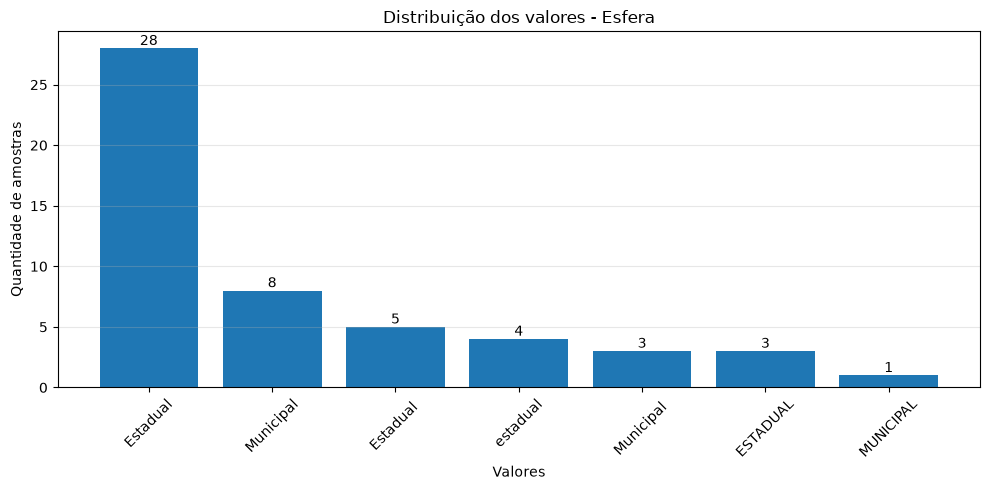

In [29]:
coluna = 'Esfera'

# Contagem de cada valor
contagem = gdf[coluna].value_counts()

# Gráfico
plt.figure(figsize=(10, 5))

barras = plt.bar(contagem.index.astype(str), contagem.values)

plt.title(f'Distribuição dos valores - {coluna}')
plt.xlabel('Valores')
plt.ylabel('Quantidade de amostras')

plt.bar_label(barras, fmt='%d')

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

                                                                                              NomeInstituicao     Esfera                     geometry
0                                                      Seção de Memorial da Câmara Vereadores de Porto Alegre  Municipal  POINT (-51.23834 -30.03783)
1                                                                                    Museu Estadual do Carvão   Estadual  POINT (-51.72272 -30.09157)
2                                     Instituto de Assistência a Saúde dos Servidores Públicos RS - IPE Saúde   Estadual  POINT (-51.22926 -30.04362)
3                                                     Tribunal de Contas do Estado RS - Memorial e Biblioteca   Estadual   POINT (-51.2353 -30.03102)
4                                                                 Arquivo Público da Prefeitura de Montenegro  Municipal  POINT (-51.45351 -29.68207)
5                                                         Núcleo de Arquivo Geral - Processos Admini

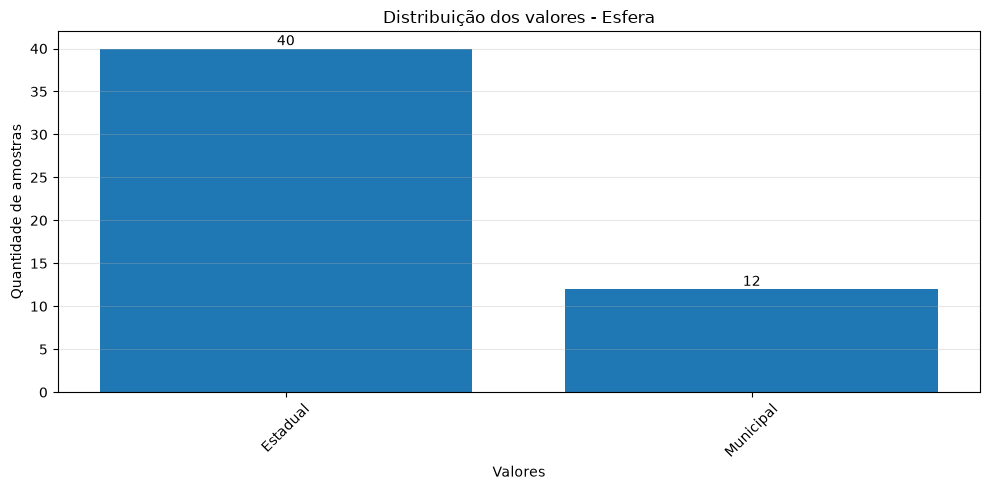

In [3]:
#-- LIMPEZA --#
gdf = gpd.read_file(
    "../dados/cheias_rhguaiba_2024_db_v14.gpkg",
    layer="rs_crise_patrimonio_cultural"
)

SIGLA = {
    "SSP", "IRGA", "DAER", "JARI", "SPGG", "DIPRO", "DETRAN", "RS", "CEDOC",
    "PGE", "SOP", "SICT", "UERGS", "COPOM", "COHAB", "CESA", "MARGS", "SJCDH",
    "CIENTEC", "IPE", "FEPAM", "EMEF", "DIPES", "SEDEC", "CAFF",
}
CONECTOR = {"de", "da", "do", "das", "dos", "e", "a", "o", "em", "na", "no"}


def normalize_ws(s):
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFC", str(s))
    return re.sub(r"\s+", " ", s).strip(" \t\n\r-–—,;")


def smart_title(s):
    if pd.isna(s):
        return s

    def fix(m):
        w = m.group(0)
        if any(c.isdigit() for c in w):
            return w
        if w.upper() in SIGLA:
            return w.upper()
        if w.lower() in CONECTOR:
            return w.lower()
        return w.capitalize() 

    out = re.sub(r"[^\W_]+\w*", fix, s)
    return out[:1].upper() + out[1:]


gdf = gdf.copy()

gdf = gdf.dropna(subset=["NomeInstituicao"])


gdf = gdf.drop(columns=["ID", "X", "Y", "NomeCidade", "Endereco"], errors="ignore")


gdf["NomeInstituicao"] = gdf["NomeInstituicao"].map(normalize_ws).map(smart_title)
gdf["Esfera"] = gdf["Esfera"].map(normalize_ws).str.capitalize()


gdf["_wkb"] = gdf.geometry.to_wkb()
gdf = gdf.drop_duplicates(subset=["NomeInstituicao", "_wkb"], keep="first")
gdf = gdf.drop(columns="_wkb").reset_index(drop=True)

print(gdf.to_string())

gdf.to_file("rs_crise_patrimonio_cultural_limpo.gpkg", layer="gdf", driver="GPKG")
#=================================
coluna = 'Esfera'

# Contagem de cada valor
contagem = gdf[coluna].value_counts()

# Gráfico
plt.figure(figsize=(10, 5))

barras = plt.bar(contagem.index.astype(str), contagem.values)

plt.title(f'Distribuição dos valores - {coluna}')
plt.xlabel('Valores')
plt.ylabel('Quantidade de amostras')

plt.bar_label(barras, fmt='%d')

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
